# Option Basics and the Black-Scholes-Merton Model

### Homework Tasks:
**a.)** Smart up our plotter to be able to customize the hard-coded layout setup inside the function. Add more custom features that you would like to use. *(4 pts)*  
**b.)** Upgrade the BSM call option pricer to be able to return the greeks as well, not just the price. *(3 pts)*  
**c.)** Implement the BSM pricer for European put option. *(3 pts)*  
**d.)** With the call and put pricer, check if Put-Call parity holds in practice *(5 pts)*  

In [ ]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
from typing import Dict, List, Union

## a.) Smarting up the Plotter

The original plotter had hardcoded dimensions, lacked visual polish, and struggled to cleanly handle plotting multiple arrays. 

**Enhancements made:**
1. **Robust Data Handling:** Uses `np.atleast_1d` and structure checks to handle single lines, multiple lines, lists, and NumPy arrays.
2. **Dynamic Layout Dictionary:** Allows users to pass a `layout` dict controlling `figsize`, `style`, `grid`, `limits`, and typography, falling back to sensible defaults.
3. **Aesthetics:** Incorporates a custom color palette and integrates `seaborn-v0_8-whitegrid` styling for a more professional, academic look.

In [ ]:
DEFAULTS = {
    "figsize": (10, 6),
    "style": "seaborn-v0_8-whitegrid",
    "title_size": 18,
    "label_size": 14,
    "legend_size": 12,
    "grid_alpha": 0.6
}

PALETTE = [
    "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", 
    "#9467bd", "#8c564b", "#e377c2", "#7f7f7f"
]

def my_plotter(
    x: Union[List[float], np.ndarray],
    y: Union[List[float], List[np.ndarray], np.ndarray],
    layout: Dict = None,
    names: List[str] = None
) -> None:
    """
    An upgraded plotter supporting dynamic layouts, grid overlays, custom colors, and robust type handling.
    """
    layout = layout or {}
    
    if isinstance(y, (list, tuple)) and not isinstance(y[0], (list, np.ndarray)):
        y_list = [np.array(y)]
    elif isinstance(y, np.ndarray) and y.ndim == 1:
        y_list = [y]
    else:
        y_list = [np.array(item) for item in y]

    plt.style.use(layout.get("style", DEFAULTS["style"]))
    fig_size = layout.get('figsize', DEFAULTS["figsize"])
    fig, ax = plt.subplots(figsize=fig_size)
    
    show_legend = bool(names)
    if show_legend and len(names) != len(y_list):
        raise ValueError("Length of names must match the number of plotted y lines.")

    # Plot each line with a custom color palette
    for i, y_item in enumerate(y_list):
        plot_kwargs = {
            'linestyle': layout.get('linestyle', 'solid'),
            'linewidth': layout.get('linewidth', 2.5),
            'color': layout.get('colors', PALETTE)[i % len(PALETTE)],
            'alpha': layout.get('alpha', 0.9)
        }
        if show_legend:
            plot_kwargs['label'] = names[i]
            
        ax.plot(x, y_item, **plot_kwargs)

    # Dynamic styling and typography
    if show_legend:
        ax.legend(fontsize=layout.get('legend_size', DEFAULTS['legend_size']), loc='best')
        
    if 'title' in layout:
        ax.set_title(layout['title'], fontsize=layout.get('title_size', DEFAULTS['title_size']), pad=15)
        
    if 'x_label' in layout:
        ax.set_xlabel(layout['x_label'], fontsize=layout.get('label_size', DEFAULTS['label_size']))
        
    if 'y_label' in layout:
        ax.set_ylabel(layout['y_label'], fontsize=layout.get('label_size', DEFAULTS['label_size']))

    if layout.get('grid', True):
        ax.grid(True, linestyle=':', alpha=layout.get('grid_alpha', DEFAULTS['grid_alpha']))

    if layout.get('show_zero_line', True):
        ax.axhline(0, linestyle='--', color='black', linewidth=1.5, alpha=0.5)

    plt.tight_layout()
    plt.show()

## b.) Upgrading the BSM Call Option Pricer (Adding Greeks)

The Black-Scholes-Merton (BSM) formula provides a theoretical estimate of the price of European options. The "Greeks" represent the sensitivities of this option price to different underlying parameters.

For a European Call Option:
* **Price ($C$):** $S_0 N(d_1) - K e^{-rT} N(d_2)$
* **Delta ($\Delta = \frac{\partial C}{\partial S}$):** $N(d_1)$
* **Gamma ($\Gamma = \frac{\partial^2 C}{\partial S^2}$):** $\frac{N'(d_1)}{S_0 \sigma \sqrt{T}}$
* **Vega ($\nu = \frac{\partial C}{\partial \sigma}$):** $S_0 \sqrt{T} N'(d_1)$
* **Theta ($\Theta = \frac{\partial C}{\partial T}$):** $-\frac{S_0 N'(d_1) \sigma}{2\sqrt{T}} - r K e^{-rT} N(d_2)$
* **Rho ($\rho = \frac{\partial C}{\partial r}$):** $K T e^{-rT} N(d_2)$

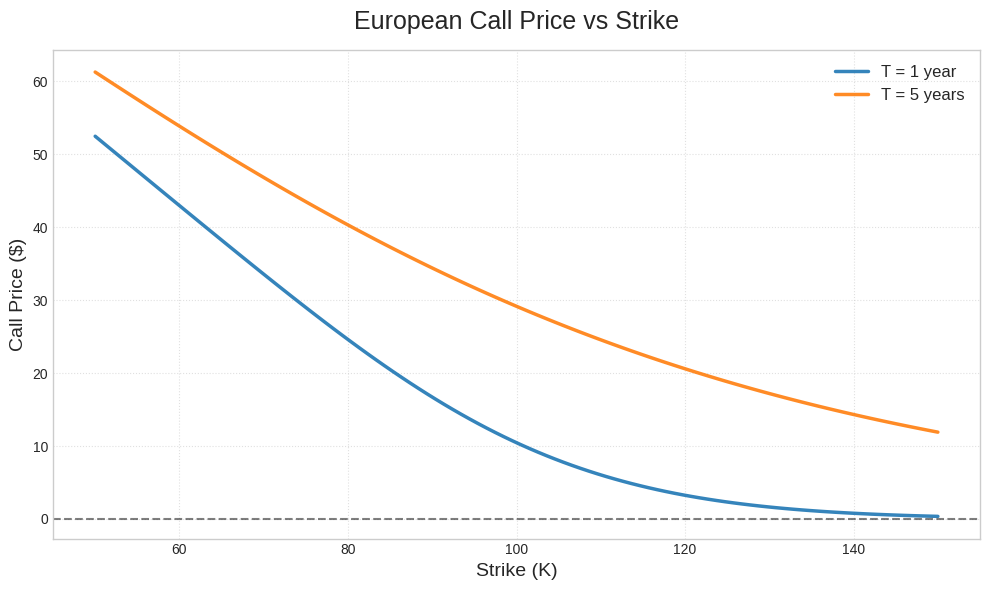

In [3]:
def black_scholes_eur_call(r: float, T: float, S0: float, sigma: float, K: Union[float, List[float], np.ndarray]) -> dict:
    """
    Calculates the BSM price and Greeks for a European Call Option.
    Returns a dictionary for clean programmatic access.
    """
    assert sigma > 0, "Volatility must be positive."
    assert T > 0, "Time to maturity must be greater than zero."

    K_vec = np.atleast_1d(K)
    sqrt_T = np.sqrt(T)

    d1 = (np.log(S0 / K_vec) + (r + 0.5 * sigma**2) * T) / (sigma * sqrt_T)
    d2 = d1 - sigma * sqrt_T

    N_d1 = norm.cdf(d1)
    N_d2 = norm.cdf(d2)
    pdf_d1 = norm.pdf(d1) 

    # Valuations
    price = S0 * N_d1 - K_vec * np.exp(-r * T) * N_d2
    
    # Greeks
    delta = N_d1
    gamma = pdf_d1 / (S0 * sigma * sqrt_T)
    vega = S0 * pdf_d1 * sqrt_T
    theta = -(S0 * pdf_d1 * sigma) / (2 * sqrt_T) - r * K_vec * np.exp(-r * T) * N_d2
    rho = K_vec * T * np.exp(-r * T) * N_d2

    return {
        'price': price,
        'delta': delta,
        'gamma': gamma,
        'vega': vega,
        'theta': theta,
        'rho': rho
    }

# Test the upgraded pricer and plotter together
K_vec = np.linspace(50, 150, 100)
call_data_1y = black_scholes_eur_call(r=0.05, T=1.0, S0=100, sigma=0.2, K=K_vec)
call_data_5y = black_scholes_eur_call(r=0.05, T=5.0, S0=100, sigma=0.2, K=K_vec)

my_plotter(
    x=K_vec, 
    y=[call_data_1y['price'], call_data_5y['price']], 
    layout={'title': 'European Call Price vs Strike', 'x_label': 'Strike (K)', 'y_label': 'Call Price ($)'},
    names=['T = 1 year', 'T = 5 years']
)

## c.) Implementing the BSM European Put Pricer

For a European Put Option, the logic is symmetrical, using $-d_1$ and $-d_2$:
* **Price ($P$):** $K e^{-rT} N(-d_2) - S_0 N(-d_1)$
* **Delta ($\Delta$):** $N(d_1) - 1 = -N(-d_1)$
* **Gamma ($\Gamma$):** Same as Call
* **Vega ($\nu$):** Same as Call
* **Theta ($\Theta$):** $-\frac{S_0 N'(d_1) \sigma}{2\sqrt{T}} + r K e^{-rT} N(-d_2)$
* **Rho ($\rho$):** $-K T e^{-rT} N(-d_2)$

<>:44: SyntaxWarning: invalid escape sequence '\D'
<>:44: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_78408/1171185111.py:44: SyntaxWarning: invalid escape sequence '\D'
  layout={'title': 'European Put Delta vs Strike', 'x_label': 'Strike (K)', 'y_label': 'Delta ($\Delta$)'},


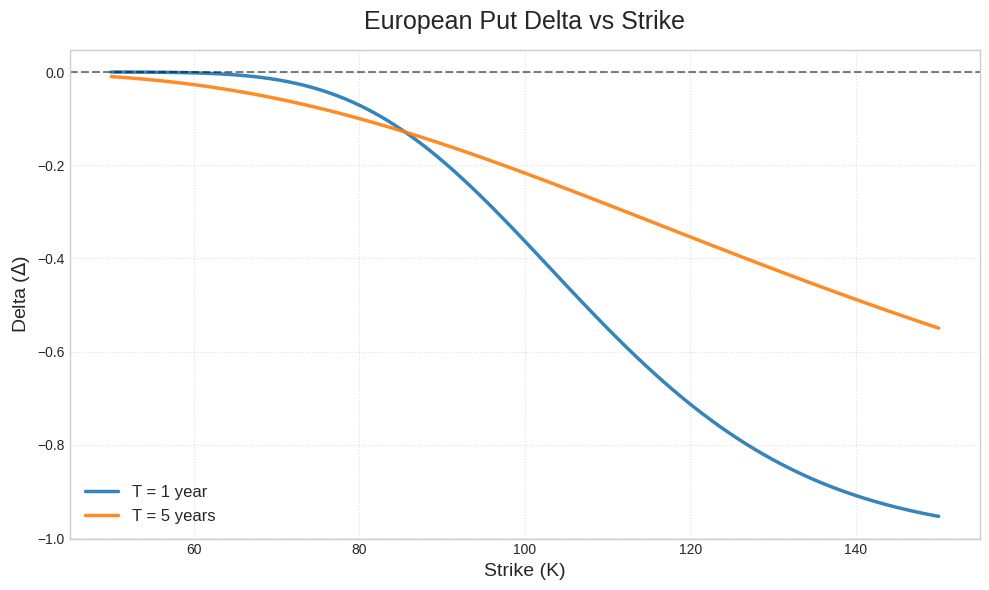

In [ ]:
def black_scholes_eur_put(r: float, T: float, S0: float, sigma: float, K: Union[float, List[float], np.ndarray]) -> dict:
    """
    Calculates the BSM price and Greeks for a European Put Option.
    """
    assert sigma > 0, "Volatility must be positive."
    assert T > 0, "Time to maturity must be greater than zero."

    K_vec = np.atleast_1d(K)
    sqrt_T = np.sqrt(T)

    d1 = (np.log(S0 / K_vec) + (r + 0.5 * sigma**2) * T) / (sigma * sqrt_T)
    d2 = d1 - sigma * sqrt_T

    N_minus_d1 = norm.cdf(-d1)
    N_minus_d2 = norm.cdf(-d2)
    pdf_d1 = norm.pdf(d1)

    # Valuations
    price = K_vec * np.exp(-r * T) * N_minus_d2 - S0 * N_minus_d1
    
    # Greeks
    delta = -N_minus_d1 
    gamma = pdf_d1 / (S0 * sigma * sqrt_T)
    vega = S0 * pdf_d1 * sqrt_T
    theta = -(S0 * pdf_d1 * sigma) / (2 * sqrt_T) + r * K_vec * np.exp(-r * T) * N_minus_d2
    rho = -K_vec * T * np.exp(-r * T) * N_minus_d2

    return {
        'price': price,
        'delta': delta,
        'gamma': gamma,
        'vega': vega,
        'theta': theta,
        'rho': rho
    }

# Visualize Put Delta
put_data_1y = black_scholes_eur_put(r=0.05, T=1.0, S0=100, sigma=0.2, K=K_vec)
put_data_5y = black_scholes_eur_put(r=0.05, T=5.0, S0=100, sigma=0.2, K=K_vec)

my_plotter(
    x=K_vec, 
    y=[put_data_1y['delta'], put_data_5y['delta']], 
    layout={'title': 'European Put Delta vs Strike', 'x_label': 'Strike (K)', 'y_label': 'Delta ($\Delta$)'},
    names=['T = 1 year', 'T = 5 years']
)

## d.) Validating Put-Call Parity

The Put-Call Parity defines the strict mathematical relationship between the price of a European Call and Put with identical strike prices and expiries:

$$C - P = S_0 - K e^{-rT}$$

We can verify this in two ways:
1. **Visually:** We plot the Long Call minus Short Put portfolio ($C - P$) alongside the mathematical Forward payoff ($S_0 - K e^{-rT}$). They should perfectly overlap.
2. **Programmatically:** We generate random scenarios and check if the parity holds using `np.isclose` (to account for floating-point inaccuracies).

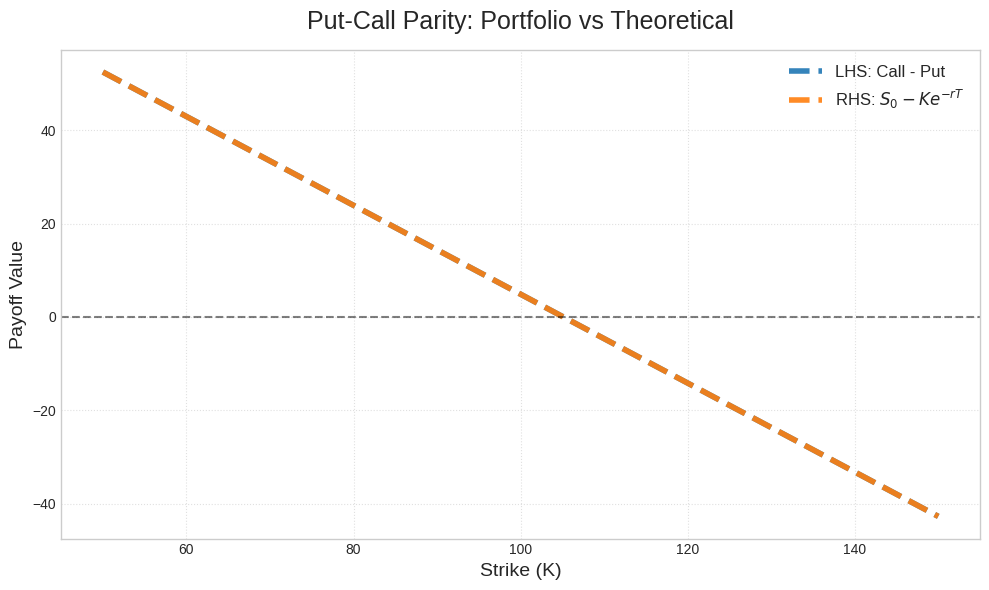

Tested 10000 random option configurations.
Maximum floating point error observed: 3.55e-14
✅ Put-Call parity holds perfectly across all tests.


In [ ]:
# 1. VISUAL VERIFICATION
r_val, T_val, S0_val, sigma_val = 0.05, 1.0, 100.0, 0.2
K_grid = np.linspace(50, 150, 200)

call_prices = black_scholes_eur_call(r=r_val, T=T_val, S0=S0_val, sigma=sigma_val, K=K_grid)['price']
put_prices = black_scholes_eur_put(r=r_val, T=T_val, S0=S0_val, sigma=sigma_val, K=K_grid)['price']

# Calculate Left-Hand Side (C - P) and Right-Hand Side (S0 - K*e^-rT)
lhs_portfolio = call_prices - put_prices
rhs_theoretical = S0_val - K_grid * np.exp(-r_val * T_val)

my_plotter(
    x=K_grid,
    y=[lhs_portfolio, rhs_theoretical],
    layout={
        'title': 'Put-Call Parity: Portfolio vs Theoretical',
        'x_label': 'Strike (K)',
        'y_label': 'Payoff Value',
        'linestyle': 'dashed',
        'linewidth': 4
    },
    names=['LHS: Call - Put', 'RHS: $S_0 - K e^{-rT}$']
)

# 2. PROGRAMMATIC VERIFICATION (Monte Carlo style)
import random

M = 10_000
parity_holds = True
max_error = 0.0

for _ in range(M):
    r = random.uniform(0.01, 0.15)
    T = random.uniform(0.1, 5.0)
    S0 = random.uniform(50, 150)
    sigma = random.uniform(0.1, 0.8)
    K = random.uniform(50, 150)
    
    C = black_scholes_eur_call(r, T, S0, sigma, K)['price'][0]
    P = black_scholes_eur_put(r, T, S0, sigma, K)['price'][0]
    
    lhs = C - P
    rhs = S0 - K * np.exp(-r * T)
    
    error = abs(lhs - rhs)
    if error > max_error:
        max_error = error
        
    if not np.isclose(lhs, rhs, atol=1e-10):
        parity_holds = False
        break

print(f"Tested {M} random option configurations.")
print(f"Maximum floating point error observed: {max_error:.2e}")
if parity_holds:
    print("Put-Call parity holds perfectly across all tests.")
else:
    print("Put-Call parity failed.")